# 04 · Exploratory data analysis
Distributions, time patterns, outliers and relationships, looked at before any business conclusions are drawn.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()

In [2]:
baskets = query(engine, "SELECT b.*, br.branch_type, COALESCE(c.customer_segment,'Anonymous') AS segment FROM retail.v_baskets b JOIN retail.branches br USING (branch_id) LEFT JOIN retail.customers c USING (customer_id)")
for c in ["basket_revenue", "basket_gross_profit"]: baskets[c] = baskets[c].astype(float)
baskets.basket_revenue.describe(percentiles=[.25, .5, .75, .95, .99])

count   289,936.00
mean      1,688.78
std       2,067.49
min          17.47
25%         610.00
50%       1,109.00
75%       1,922.00
95%       5,328.01
99%      10,840.30
max      38,680.00
Name: basket_revenue, dtype: float64

## 1. Basket value distribution
The distribution is strongly right-skewed: the mean sits above the median, so **ATV is pulled up by a minority of large baskets**. This is why the dashboard shows the median next to the mean.

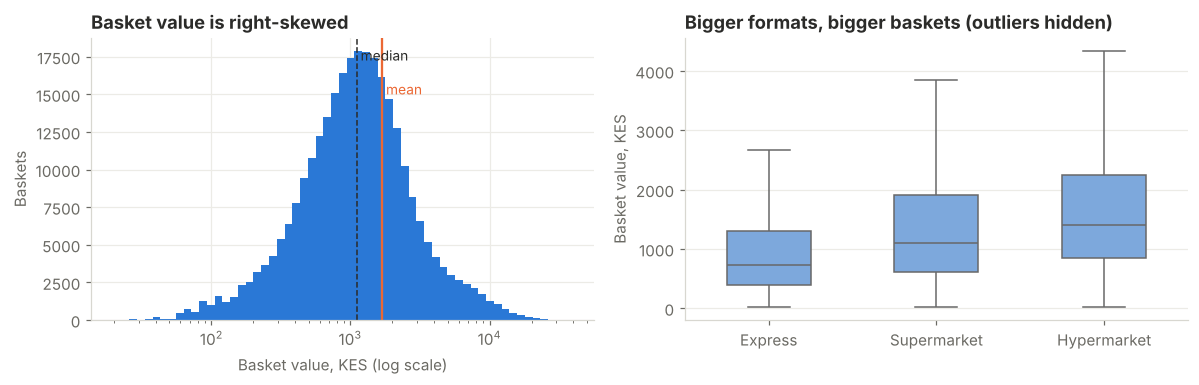

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.hist(baskets.basket_revenue, bins=np.logspace(1.3, np.log10(baskets.basket_revenue.max()), 60), color=an.PRIMARY)
ax.set_xscale("log"); ax.set_xlabel("Basket value, KES (log scale)"); ax.set_ylabel("Baskets")
ax.axvline(baskets.basket_revenue.median(), color=an.INK, lw=1, ls="--"); ax.axvline(baskets.basket_revenue.mean(), color=an.HIGHLIGHT, lw=1.5)
ax.text(baskets.basket_revenue.median(), ax.get_ylim()[1]*.92, " median", fontsize=9); ax.text(baskets.basket_revenue.mean(), ax.get_ylim()[1]*.8, " mean", color=an.HIGHLIGHT, fontsize=9)
ax.set_title("Basket value is right-skewed")
ax = axes[1]
order = ["Express", "Supermarket", "Hypermarket"]
sns.boxplot(data=baskets, x="branch_type", y="basket_revenue", order=order, ax=ax, color=an.SEQ_BLUES[2], showfliers=False, width=.5)
ax.set_xlabel(""); ax.set_ylabel("Basket value, KES"); ax.set_title("Bigger formats, bigger baskets (outliers hidden)")
fig.tight_layout(); an.save(fig, "eda_basket_distribution");

In [4]:
baskets.groupby('segment').agg(baskets=('transaction_id','count'), median_value=('basket_revenue','median'), mean_value=('basket_revenue','mean'), mean_units=('units','mean')).sort_values('mean_value', ascending=False)

,baskets,median_value,mean_value,mean_units
segment,,,,
Small Business,38219,"4,196.00","5,092.99",22.42
Senior,10731,995.07,"1,199.81",5.52
Household,100393,999.00,"1,187.08",5.48
Anonymous,110590,996.00,"1,186.60",5.49
Young Professional,30003,873.00,"1,057.02",4.88


## 2. Outliers: who are the largest baskets?

In [5]:
top = baskets.nlargest(200, "basket_revenue")
top.segment.value_counts(normalize=True).mul(100).round(1).to_frame("% of top-200 baskets")

,% of top-200 baskets
segment,
Small Business,100.00


All of the 200 largest baskets belong to Small Business customers (kiosk owners restocking). They are **genuine and kept**, and they are a segment to serve deliberately rather than noise to remove.

## 3. Time patterns

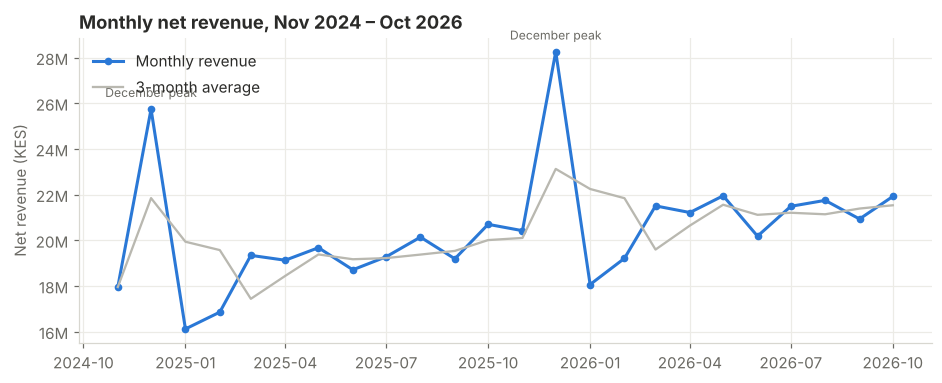

In [6]:
m = an.sql_output("q02_monthly_revenue_mom"); m["sale_month"] = pd.to_datetime(m["sale_month"])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(m.sale_month, m.revenue_kes, color=an.PRIMARY, marker="o", ms=4, label="Monthly revenue")
ax.plot(m.sale_month, m.revenue_3m_avg_kes, color=an.CONTEXT, lw=1.5, label="3-month average")
for _, r in m[m.sale_month.dt.month == 12].iterrows():
    ax.annotate("December peak", (r.sale_month, r.revenue_kes), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=an.INK_MUTED)
an.kes_axis(ax); ax.set_ylabel("Net revenue (KES)"); ax.set_title("Monthly net revenue, Nov 2024 – Oct 2026"); ax.legend(loc="upper left")
an.save(fig, "eda_monthly_revenue");

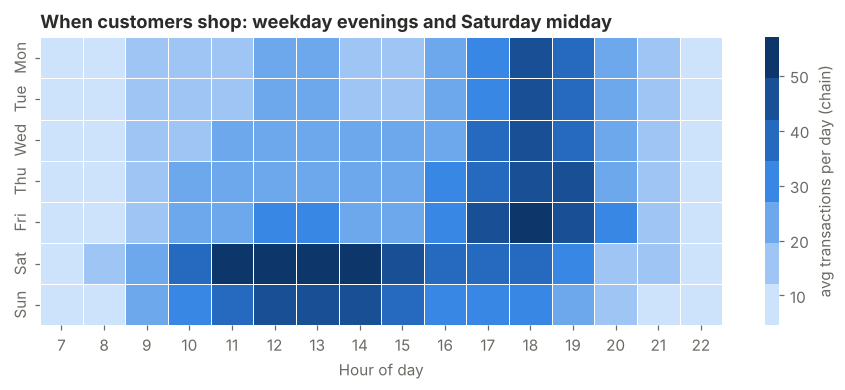

In [7]:
hm = query(engine, "SELECT EXTRACT(ISODOW FROM transaction_ts)::int AS dow, EXTRACT(HOUR FROM transaction_ts)::int AS hour, COUNT(*) AS n FROM retail.transactions GROUP BY 1,2")
pivot = hm.pivot(index="dow", columns="hour", values="n")
days = query(engine, "SELECT iso_dow AS dow, COUNT(*) AS days FROM retail.v_dim_date GROUP BY 1").set_index("dow").days
pivot = pivot.div(days, axis=0)   # average transactions per calendar day, per hour
pivot.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.heatmap(pivot, cmap=sns.color_palette(an.SEQ_BLUES, as_cmap=True), ax=ax, cbar_kws={"label": "avg transactions per day (chain)"}, linewidths=.5, linecolor="white")
ax.set_xlabel("Hour of day"); ax.set_ylabel(""); ax.set_title("When customers shop: weekday evenings and Saturday midday")
an.save(fig, "eda_dow_hour_heatmap");

## 4. Relationships between variables

Spearman correlation, basket units vs basket value: 0.833


Spearman correlation, product revenue vs margin: -0.453


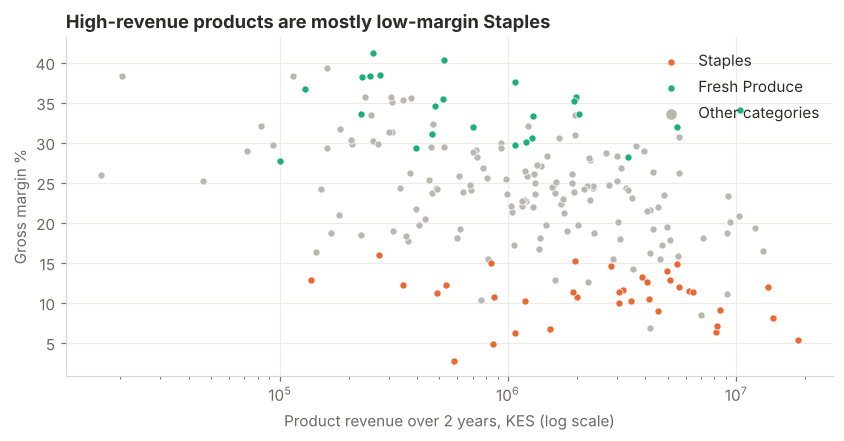

In [8]:
print("Spearman correlation, basket units vs basket value:", round(baskets[["units", "basket_revenue"]].corr(method="spearman").iloc[0, 1], 3))
lines = an.load_sales_lines(engine, "product_id, category, quantity, gross_sales, discount_amount, net_revenue, gross_profit")
prod = lines.groupby(["product_id", "category"]).agg(rev=("net_revenue", "sum"), gp=("gross_profit", "sum"), disc=("discount_amount", "sum"), gs=("gross_sales", "sum")).reset_index()
prod["margin"] = 100 * prod.gp / prod.rev; prod["disc_rate"] = 100 * prod.disc / prod.gs
fig, ax = plt.subplots(figsize=(9, 4))
cats = prod.groupby("category").rev.sum().sort_values(ascending=False).index
hi = {"Staples": an.HIGHLIGHT, "Fresh Produce": an.SECOND}
for c in cats:
    d = prod[prod.category == c]
    ax.scatter(d.rev, d.margin, s=22, color=hi.get(c, an.CONTEXT), label=c if c in hi else None, edgecolor="white", lw=.5, zorder=3 if c in hi else 2)
ax.set_xscale("log"); ax.set_xlabel("Product revenue over 2 years, KES (log scale)"); ax.set_ylabel("Gross margin %")
ax.scatter([], [], color=an.CONTEXT, label="Other categories"); ax.legend(loc="upper right")
ax.set_title("High-revenue products are mostly low-margin Staples")
an.save(fig, "eda_revenue_vs_margin");
print("Spearman correlation, product revenue vs margin:", round(prod[["rev", "margin"]].corr(method="spearman").iloc[0, 1], 3))

**Observations to carry forward**
1. Revenue is seasonal: December is the peak, January dips, and paydays and weekends lift daily sales. Comparisons should be year-over-year, not month-over-month, where seasonality matters.
2. Product revenue and margin are **negatively correlated**. The biggest sellers (cooking oil, sugar, flour) carry single-digit margins, so *revenue rank is a poor guide to profit contribution*.
3. Large baskets are real Small Business purchases, a segment worth managing explicitly.